# Anomaly detection trained on accepted batches only (RDST + PCA)

Second solution of Project 2: learn **normal** behaviour from accepted batches only, flag anything that deviates, and show **where** it deviates. Self-contained: only needs the data folder.

1. **Features** - RDST shapelets drawn from accepted batches (local patterns of normal runs) + a spread block per sensor (std, mean step, range: fast noise).
2. **Score** - PCA fitted on accepted batches. **T2**: unusual but inside normal variation; **SPE**: something normal batches never show. Score = T2 + SPE (each scaled by its accepted median).
3. **Threshold** - 95th percentile of the scores of accepted batches held apart for calibration. Rejected labels are never used to fit; only to evaluate.
4. **Explanation** - share of the score per sensor, and the part of the batch where the sensor leaves the band of accepted batches.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from aeon.transformations.collection.shapelet_based import RandomDilatedShapeletTransform
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 0
LENGTH = 1000     # every batch becomes 1000 points per sensor
QUANTILE = 0.95   # threshold: 95th percentile of accepted calibration scores
VAR_KEPT = 0.90   # PCA keeps 90% of the variance of accepted batches

# first data folder that exists (Renku or a local copy)
candidates = ["../../input-data/Project 2 - BRPMM", "../input-data/Project 2 - BRPMM",
              "/home/renku/work/input-data/Project 2 - BRPMM", "../../Project 2 - BRPMM"]
DATA_DIR = next(Path(c) for c in candidates if Path(c).is_dir())
print(DATA_DIR.resolve())

/home/renku/work/input-data/Project 2 - BRPMM


## Data

In [2]:
def load(process):
    """Batches of the calibration data in label order: list of (rows x sensors) arrays, labels (1 = rejected), ids, sensors."""
    d = DATA_DIR / f"process {process}" / "calibration data"
    df = pd.read_csv(d / "calibration_data.csv", dtype={"batch_id": str})
    sensors = [c for c in df.columns if c != "batch_id"]
    groups = {b: g[sensors].to_numpy(float) for b, g in df.groupby("batch_id")}
    lab = pd.read_csv(d / "calibration_labels.csv", dtype={"batch_id": str})
    ids = list(lab.batch_id)
    return [groups[b] for b in ids], lab.label.eq("rejected").astype(int).to_numpy(), ids, sensors


def fixed_length(a):
    """Cut the batch into LENGTH equal slices and average each one -> (sensors x LENGTH)."""
    n = len(a)
    if n < LENGTH:  # short batch: stretch it instead
        old, new = np.linspace(0, 1, n), np.linspace(0, 1, LENGTH)
        return np.stack([np.interp(new, old, a[:, j]) for j in range(a.shape[1])])
    slice_id = np.arange(n) * LENGTH // n
    sums = np.zeros((LENGTH, a.shape[1]))
    np.add.at(sums, slice_id, a)
    return (sums / np.bincount(slice_id, minlength=LENGTH)[:, None]).T


def spread(arrays):
    """Per sensor: log of std, of mean step size and of range (fast noise the slice means erase)."""
    return np.array([np.log(np.concatenate([a.std(0), np.abs(np.diff(a, axis=0)).mean(0), a.max(0) - a.min(0)]) + 1e-6)
                     for a in arrays])

## Model (fitted on accepted batches only)

In [3]:
class AnomalyModel:
    def fit(self, X, arrays, X_cal, arrays_cal):
        self.mu = X.mean(axis=(0, 2), keepdims=True)
        self.sd = X.std(axis=(0, 2), keepdims=True); self.sd[self.sd == 0] = 1
        self.rdst = RandomDilatedShapeletTransform(random_state=SEED, n_jobs=1)
        F = self._clean(self.rdst.fit_transform((X - self.mu) / self.sd, np.zeros(len(X), int)))
        G = spread(arrays)
        self.sc_r, self.sc_s, self.n_rdst = StandardScaler().fit(F), StandardScaler().fit(G), F.shape[1]
        Z = self._join(F, G)
        self.pca = PCA(n_components=VAR_KEPT, svd_solver="full").fit(Z)
        t2, spe = self._stats(Z)
        self.m_t2, self.m_spe = np.median(t2), np.median(spe)
        self.threshold = np.quantile(self.score(X_cal, arrays_cal), QUANTILE)
        return self

    def _clean(self, F):
        return np.nan_to_num(np.asarray(F, float), nan=0.0, posinf=0.0, neginf=0.0)

    def _join(self, F, G):  # each block standardised and given the same total weight
        return np.hstack([self.sc_r.transform(F) / np.sqrt(F.shape[1]), self.sc_s.transform(G) / np.sqrt(G.shape[1])])

    def _z(self, X, arrays):
        return self._join(self._clean(self.rdst.transform((X - self.mu) / self.sd)), spread(arrays))

    def _stats(self, Z):
        T = self.pca.transform(Z)
        return (T ** 2 / self.pca.explained_variance_).sum(1), ((Z - self.pca.inverse_transform(T)) ** 2).sum(1)

    def score(self, X, arrays):
        t2, spe = self._stats(self._z(X, arrays))
        return t2 / self.m_t2 + spe / self.m_spe

    def contributions(self, X, arrays, sensors):
        """Share of the score per sensor (spread block) and for the shapelets (they span all sensors)."""
        Z = self._z(X, arrays); T = self.pca.transform(Z)
        c = np.abs((Z - self.pca.inverse_transform(T)) ** 2 / self.m_spe
                   + Z * ((T / self.pca.explained_variance_) @ self.pca.components_) / self.m_t2)
        n, sp = len(sensors), c[:, self.n_rdst:]
        out = pd.DataFrame({"shapelets (all sensors)": c[:, :self.n_rdst].sum(1)})
        for j, s in enumerate(sensors):
            out[s] = sp[:, [j, n + j, 2 * n + j]].sum(1)
        return out.div(out.sum(1), axis=0)


def fit_on(idx, X, arrays):
    """Fit on the accepted batches idx: 75% to learn normal behaviour, 25% to set the threshold."""
    fit_idx, cal_idx = train_test_split(idx, test_size=0.25, random_state=SEED)
    return AnomalyModel().fit(X[fit_idx], [arrays[i] for i in fit_idx], X[cal_idx], [arrays[i] for i in cal_idx])


def band_explanation(X_acc, x, sensors, window=50):
    """Where each sensor of batch x leaves the band of accepted batches (robust z over time)."""
    med = np.median(X_acc, 0)
    mad = np.maximum(np.median(np.abs(X_acc - med), 0) * 1.4826, 0.1 * X_acc.std(axis=(0, 2))[:, None] + 1e-9)
    z = np.abs((x - med) / mad)
    zs = np.array([np.convolve(r, np.ones(window) / window, mode="valid") for r in z])
    rows = [{"sensor": s, "worst_z": zs[j].max(), "worst_from_%": round(100 * zs[j].argmax() / x.shape[1]),
             "worst_to_%": round(100 * (zs[j].argmax() + window) / x.shape[1])} for j, s in enumerate(sensors)]
    return pd.DataFrame(rows).sort_values("worst_z", ascending=False)

## 1. Cross-validation
Accepted batches are split in 5 folds; each fold is scored by a model trained on the other accepted batches, and every rejected batch is scored too (average over folds).

In [4]:
def cross_validate(process):
    arrays, y, ids, _ = load(process)
    X = np.stack([fixed_length(a) for a in arrays])
    acc, rej = np.where(y == 0)[0], np.where(y == 1)[0]
    rows = []
    for tr, te in KFold(5, shuffle=True, random_state=SEED).split(acc):
        m = fit_on(acc[tr], X, arrays)
        idx = np.r_[acc[te], rej]
        s = m.score(X[idx], [arrays[i] for i in idx])
        rows += [{"batch_id": ids[i], "y": y[i], "score": v, "flag": int(v > m.threshold)} for i, v in zip(idx, s)]
    r = pd.DataFrame(rows).groupby("batch_id").agg(y=("y", "first"), score=("score", "mean"), flag=("flag", "mean"))
    pred = (r.flag >= 0.5).astype(int)
    print(f"process {process}: AUC {roc_auc_score(r.y, r.score):.3f} | F1 rejected {f1_score(r.y, pred):.3f} | "
          f"caught {((pred == 1) & (r.y == 1)).sum()}/{r.y.sum()} | false alarms {((pred == 1) & (r.y == 0)).sum()}/{(r.y == 0).sum()}")
    return r

cv = {p: cross_validate(p) for p in ("A", "B")}

process A: AUC 0.787 | F1 rejected 0.554 | caught 18/40 | false alarms 7/121


process B: AUC 0.994 | F1 rejected 0.500 | caught 5/5 | false alarms 10/35


## 2. Model on all accepted batches of A

In [5]:
def setup(process):
    global arrays, y, ids, sensors, X, X_acc, model, table, contrib
    arrays, y, ids, sensors = load(process)
    X = np.stack([fixed_length(a) for a in arrays])
    acc = np.where(y == 0)[0]
    model, X_acc = fit_on(acc, X, arrays), X[acc]
    scores = pd.Series(model.score(X, arrays), index=ids)
    table = pd.DataFrame({"score": scores, "flagged": scores > model.threshold, "label": np.where(y == 1, "rejected", "accepted")})
    contrib = model.contributions(X, arrays, sensors); contrib.index = ids
    print(f"threshold {model.threshold:.2f} | flagged {table.flagged.sum()} (rejected among them: {(table.flagged & (table.label == 'rejected')).sum()})")

setup("A")
table.sort_values("score", ascending=False).head(15)

threshold 5.09 | flagged 20 (rejected among them: 18)


/tmp/ipykernel_4720/904226920.py:42: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  return out.div(out.sum(1), axis=0)


,score,flagged,label
A_239,107.878970,True,accepted
A_215,99.275862,True,rejected
A_274,94.297364,True,rejected
A_048,93.711299,True,rejected
A_051,62.462923,True,rejected
A_232,61.327695,True,rejected
A_189,43.013047,True,rejected
A_298,34.281067,True,rejected
A_263,33.179483,True,rejected
A_256,13.773880,True,rejected


## 3. Where did it fail? Share of the score per sensor (flagged batches)

In [6]:
contrib.loc[table.flagged].round(2).style.background_gradient(axis=1)

,shapelets (all sensors),flow_rate_1,density,flow_rate_2,pressure_1,temperature_1,temperature_2,temperature_3,temperature_4,pressure_2,pressure_3,pressure_4
A_048,0.980000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A_051,0.970000,0.000000,0.000000,0.000000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.010000
A_059,0.790000,0.000000,0.070000,0.030000,0.010000,0.020000,0.000000,0.010000,0.040000,0.010000,0.010000,0.000000
A_078,0.920000,0.000000,0.000000,0.010000,0.000000,0.000000,0.030000,0.010000,0.020000,0.000000,0.000000,0.000000
A_100,0.380000,0.000000,0.040000,0.000000,0.010000,0.460000,0.000000,0.010000,0.070000,0.010000,0.010000,0.010000
A_135,0.820000,0.030000,0.030000,0.010000,0.030000,0.030000,0.010000,0.020000,0.010000,0.010000,0.010000,0.010000
A_189,0.290000,0.000000,0.030000,0.000000,0.010000,0.540000,0.000000,0.000000,0.090000,0.010000,0.000000,0.010000
A_209,0.940000,0.010000,0.000000,0.000000,0.000000,0.020000,0.010000,0.010000,0.000000,0.000000,0.000000,0.010000
A_215,0.980000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A_226,0.970000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.010000


## 4. One batch in detail

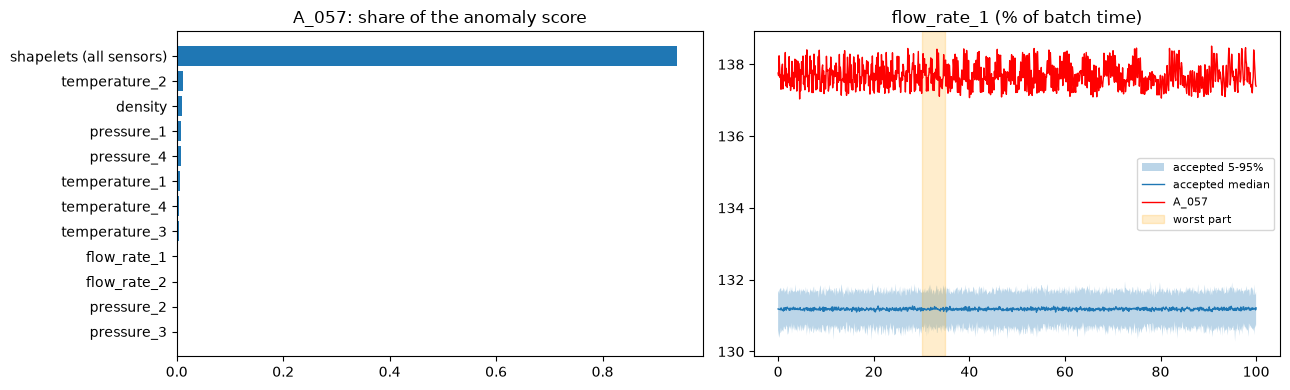

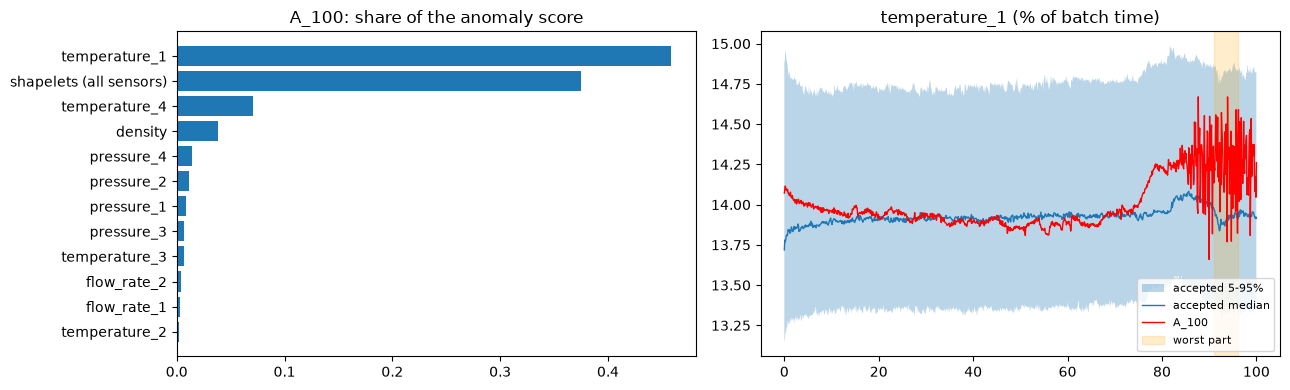

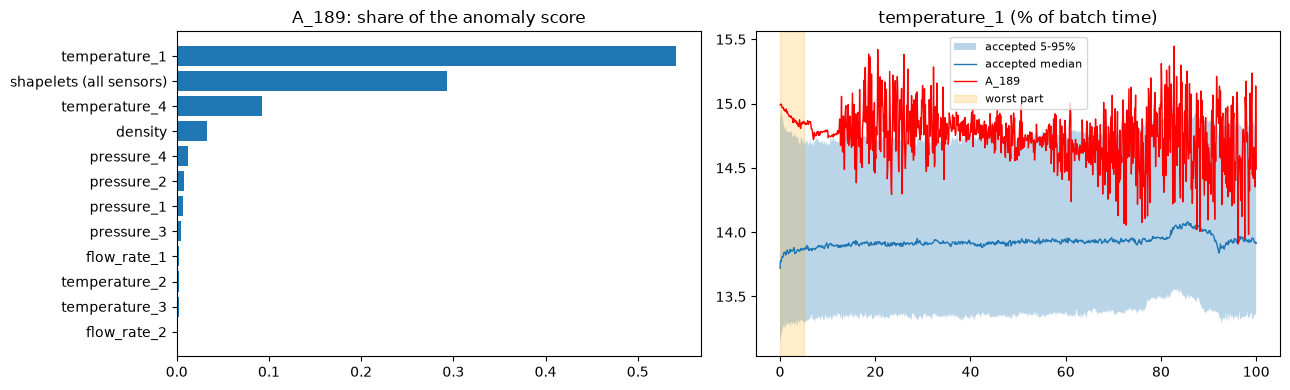

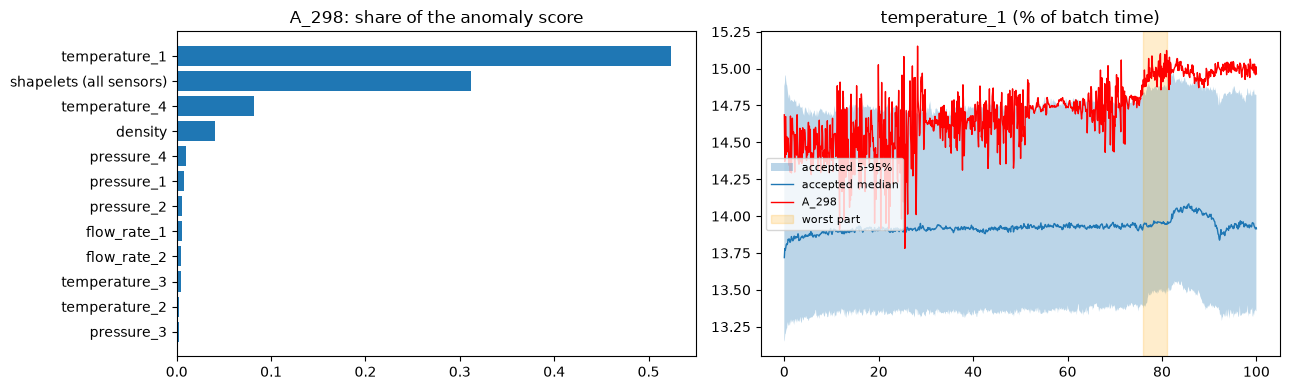

In [7]:
def explain(batch_id):
    i = ids.index(batch_id)
    c = contrib.loc[batch_id].sort_values()
    band = band_explanation(X_acc, X[i], sensors)
    top = c.index[-1]                                   # largest share of the score
    name = top if top in sensors else band.iloc[0].sensor
    s = band.set_index("sensor").loc[name]
    j = sensors.index(name)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].barh(c.index, c.values); ax[0].set_title(f"{batch_id}: share of the anomaly score")
    t = np.linspace(0, 100, X.shape[2])
    lo, med, hi = np.percentile(X_acc[:, j], [5, 50, 95], axis=0)
    ax[1].fill_between(t, lo, hi, alpha=0.3, label="accepted 5-95%")
    ax[1].plot(t, med, lw=1, label="accepted median")
    ax[1].plot(t, X[i, j], lw=1, color="red", label=batch_id)
    ax[1].axvspan(s["worst_from_%"], s["worst_to_%"], color="orange", alpha=0.2, label="worst part")
    ax[1].set_title(f"{name} (% of batch time)"); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

for b in ["A_057", "A_100", "A_189", "A_298"]:
    explain(b)

## 5. Process B

/tmp/ipykernel_4720/904226920.py:42: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  return out.div(out.sum(1), axis=0)


threshold 7.16 | flagged 6 (rejected among them: 5)


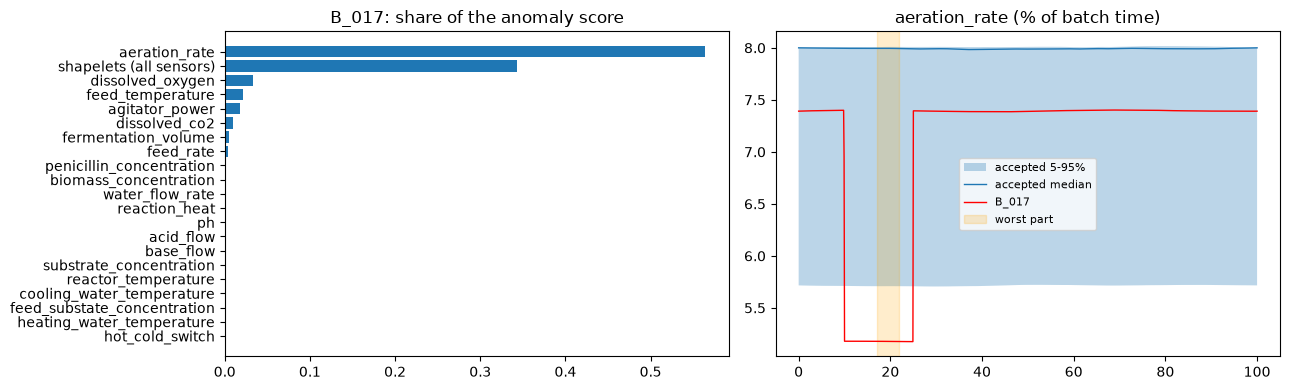

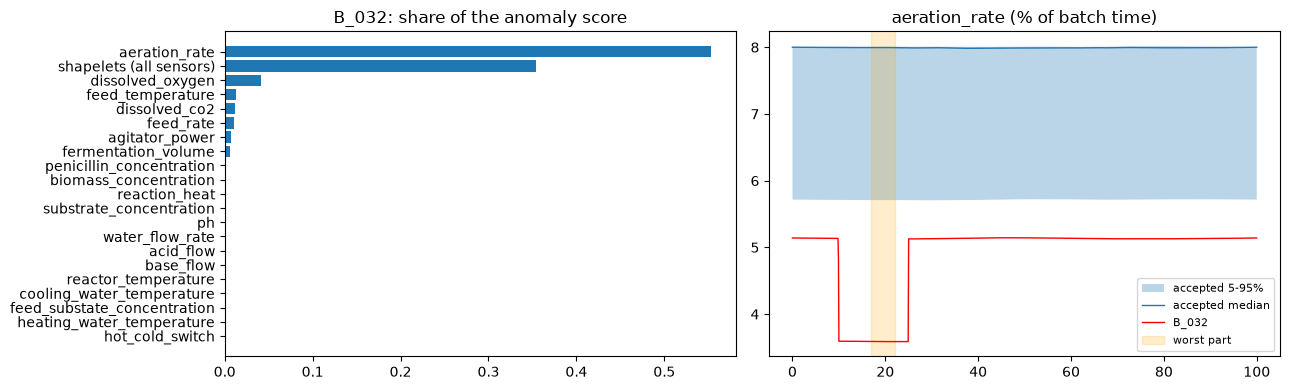

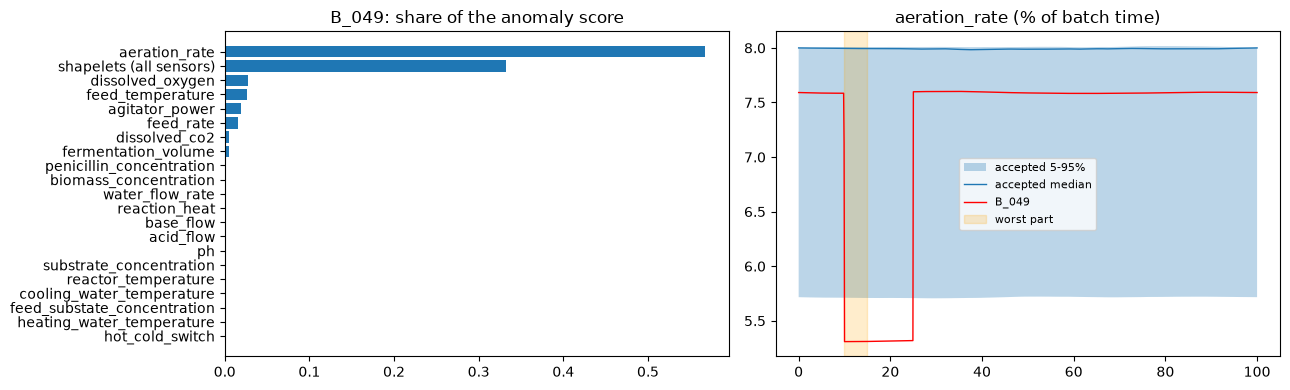

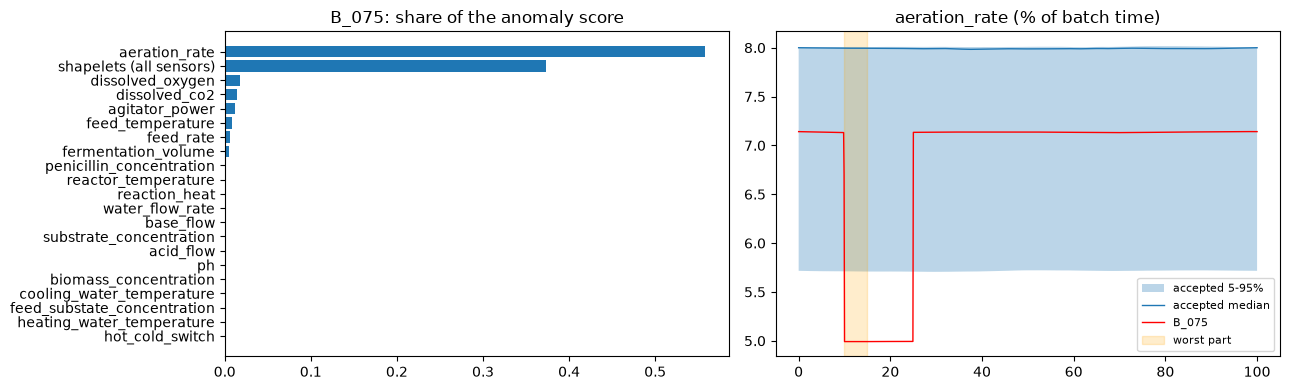

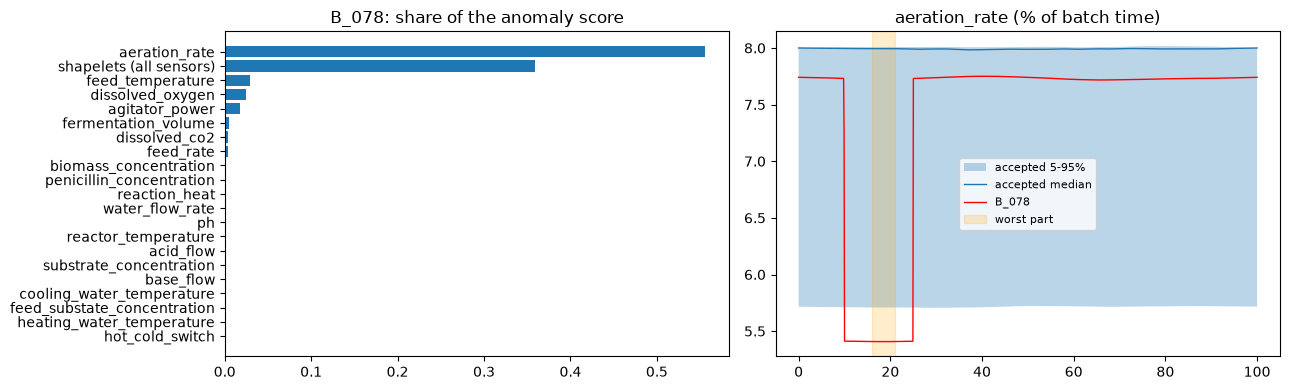

In [8]:
setup("B")
for b in table.index[table.label == "rejected"]:
    explain(b)